# Validation with a second SST dataset

Processes OISST and CCI/C3S in exactly the same way over 1982–2024 and repeats the leakage analysis, honest and exceedance persistence, and the logistic SST model; then diagnoses where the two products disagree.

**Thesis:** Sections 3.13, 4.9 · Tables 4.10–4.13 · Fig. 4.12 · Appendix C.10  
**Input:** predictor_table_1982_2025.csv, cci_sst/cci_box_YYYY.csv (from notebook 08)  
**Output:** v2_*.csv

Runs on Google Colab with the folder layout described in the repository README (`/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/...`). The printed outputs below are from the original run used in the thesis.

V2-1

In [1]:
from google.colab import drive
import os
import shutil

# Unmount first to clean up any active or stale mounts
try:
    drive.flush_and_unmount()
except Exception:
    pass

# If the directory still contains files, clean it up manually
mountpoint = '/content/drive'
if os.path.exists(mountpoint) and os.listdir(mountpoint):
    print(f"Cleaning up non-empty directory: {mountpoint}")
    try:
        shutil.rmtree(mountpoint)
    except Exception as e:
        # If it's a locked mount, we can try to unmount via shell
        !umount -l /content/drive

# Mount Google Drive
drive.mount('/content/drive', force_remount=True)

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


In [2]:
# ================= V2-1  OISST vs CCI/C3S: same processing on both, 1982-2024 (self-contained) =================
import os, glob, time, numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
PROC = os.environ.get('PROC', '/content/drive/MyDrive/Colab Notebooks/MHW_Project_Data/processed')
FIG  = f'{PROC}/figures'; os.makedirs(FIG, exist_ok=True)
END  = '2024-12-31'
df   = pd.read_csv(f'{PROC}/predictor_table_1982_2025.csv', index_col=0, parse_dates=True)
cci  = pd.concat([pd.read_csv(f, index_col=0, parse_dates=True) for f in sorted(glob.glob(f'{PROC}/cci_sst/cci_box_*.csv'))]).sst
S    = pd.DataFrame({'OISST': df.sst[:END], 'CCI': cci}).dropna()
assert len(S) == len(pd.date_range('1982-01-01', END)), f'{len(S)} days: a CCI year is missing'
YEARS = sorted(S.index.year.unique()); B = 2000
rng = np.random.default_rng(0); BIDX = rng.integers(0, len(YEARS), (B, len(YEARS)))

def doy366(idx):
    d = idx.dayofyear.values.copy(); d[(~idx.is_leap_year) & (idx.month > 2)] += 1
    return d

def hobday_clim(s, base=(1982, 2021), win=5, smooth=31, pct=90):
    """Hobday et al. (2016) climatological mean and 90th-percentile threshold, as in WP1."""
    v, d = s.values, doy366(s.index)
    inb = (s.index.year >= base[0]) & (s.index.year <= base[1])
    m, p = np.full(367, np.nan), np.full(367, np.nan)
    for k in range(1, 367):
        if k == 60: continue
        idx  = np.where((d == k) & inb)[0]
        pool = np.unique(np.clip((idx[:, None] + np.arange(-win, win + 1)).ravel(), 0, len(v) - 1))
        x = v[pool[inb[pool]]]; m[k], p[k] = np.nanmean(x), np.nanpercentile(x, pct)
    out = []
    for c in (m, p):
        c[60] = (c[59] + c[61]) / 2; c = c[1:]
        c = np.convolve(np.r_[c[-(smooth // 2):], c, c[:smooth // 2]], np.ones(smooth) / smooth, 'valid')
        out.append(pd.Series(c[d - 1], index=s.index))
    return out

def detect(exc, min_dur=5, max_gap=2):
    e = np.asarray(exc, int); n = len(e)
    b = np.diff(np.r_[0, e, 0]); st, en = np.where(b == 1)[0], np.where(b == -1)[0] - 1
    keep = en - st + 1 >= min_dur; st, en = st[keep], en[keep]
    causal, nojoin = np.zeros(n, int), np.zeros(n, int)
    for s0, e0 in zip(st, en): nojoin[s0:e0 + 1] = 1; causal[s0 + min_dur - 1:e0 + 1] = 1
    label = nojoin.copy()
    for k in range(len(st) - 1):
        if st[k + 1] - en[k] - 1 <= max_gap: label[en[k] + 1:st[k + 1]] = 1
    return causal, label

def mcc(tp, fp, fn, tn):
    tp, fp, fn, tn = (np.asarray(v, float) for v in (tp, fp, fn, tn))
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return np.where(den > 0, (tp * tn - fp * fn) / np.where(den > 0, den, 1), 0.0)

def counts(p, y, yr):
    g = pd.DataFrame({'tp': (p == 1) & (y == 1), 'fp': (p == 1) & (y == 0), 'fn': (p == 0) & (y == 1),
                      'tn': (p == 0) & (y == 0), 'yr': yr}).groupby('yr').sum()
    return g.reindex(YEARS, fill_value=0).values                       # years x 4

point = lambda c: float(mcc(*c.sum(0)))
boot  = lambda c: mcc(*c[BIDX].sum(1).T)
ci    = lambda d: f'{np.percentile(d, 2.5):+.3f} to {np.percentile(d, 97.5):+.3f}'

D = {}
for name in ('OISST', 'CCI'):
    s = S[name]; tc = np.arange(len(s)) - (len(s) - 1) / 2
    slope = (s.values * tc).sum() / (tc ** 2).sum()
    sd = s - slope * tc
    clim, thr = hobday_clim(sd)
    exc = (sd > thr).astype(int).values
    causal, label = detect(exc)
    D[name] = dict(sst=s, sdet=sd, clim=clim, thr=thr, exc=exc, causal=causal, label=label, trend=slope * 3652.5)

def events(lab):
    b = np.diff(np.r_[0, lab, 0]); st, en = np.where(b == 1)[0], np.where(b == -1)[0] - 1
    return len(st), int(np.median(en - st + 1))
a, b = D['OISST'], D['CCI']
anomA, anomB = a['sdet'] - a['clim'], b['sdet'] - b['clim']
agree = counts(b['label'], a['label'], S.index.year.values)
cmp = {'mean SST (degC)': (a['sst'].mean(), b['sst'].mean()), 'trend (degC/decade)': (a['trend'], b['trend']),
       'MHW events (detrended)': (events(a['label'])[0], events(b['label'])[0]),
       'MHW days (detrended)': (int(a['label'].sum()), int(b['label'].sum())),
       'median event duration (days)': (events(a['label'])[1], events(b['label'])[1]),
       'MHW days known only in hindsight (%)': (100 * ((a['label'] == 1) & (a['causal'] == 0)).sum() / a['label'].sum(),
                                                100 * ((b['label'] == 1) & (b['causal'] == 0)).sum() / b['label'].sum())}
CMP = pd.DataFrame(cmp, index=['OISST', 'CCI']).T.round(3)
CMP.to_csv(f'{PROC}/v2_dataset_comparison.csv')
print(CMP.to_string())
print(f'\ncorrelation of daily SST {np.corrcoef(a["sst"], b["sst"])[0, 1]:.3f} | of detrended daily anomalies {np.corrcoef(anomA, anomB)[0, 1]:.3f}')
print(f'mean difference CCI-OISST {(b["sst"] - a["sst"]).mean():+.3f} degC | RMS difference of anomalies {np.sqrt(((anomB - anomA) ** 2).mean()):.3f} degC')
print(f'agreement of daily MHW labels: MCC {point(agree):.3f} | '
      f'{100 * ((a["label"] == 1) & (b["label"] == 1)).sum() / a["label"].sum():.1f}% of OISST MHW days are also MHW days in CCI')



                                         OISST       CCI
mean SST (degC)                         28.065    28.203
trend (degC/decade)                      0.207     0.126
MHW events (detrended)                 105.000    91.000
MHW days (detrended)                  1161.000  1284.000
median event duration (days)             8.000    10.000
MHW days known only in hindsight (%)    40.913    32.165

correlation of daily SST 0.970 | of detrended daily anomalies 0.751
mean difference CCI-OISST +0.138 degC | RMS difference of anomalies 0.327 degC
agreement of daily MHW labels: MCC 0.457 | 52.5% of OISST MHW days are also MHW days in CCI


In [3]:
# ================= V2-2  benchmark leakage with both datasets =================
LEADS1 = [1, 2, 3, 5, 7, 10, 14]; rows = []
for name in ('OISST', 'CCI'):
    L = D[name]
    for h in LEADS1:
        y, yr = L['label'][h:], S.index.year.values[h:]
        cl, cc = counts(L['label'][:-h], y, yr), counts(L['causal'][:-h], y, yr)
        d = boot(cl) - boot(cc)
        rows.append({'dataset': name, 'lead': h, 'label-based': round(point(cl), 3), 'honest': round(point(cc), 3),
                     'inflation': round(point(cl) - point(cc), 3), 'inflation 95% CI': ci(d), 'lo': np.percentile(d, 2.5),
                     'hi': np.percentile(d, 97.5)})
LK = pd.DataFrame(rows); LK.to_csv(f'{PROC}/v2_leakage_both.csv', index=False)
print(LK.drop(columns=['lo', 'hi']).pivot(index='lead', columns='dataset').to_string())



        label-based        honest        inflation         inflation 95% CI                  
dataset         CCI  OISST    CCI  OISST       CCI  OISST               CCI             OISST
lead                                                                                         
1             0.923  0.902  0.720  0.631     0.203  0.271  +0.176 to +0.241  +0.241 to +0.309
2             0.846  0.805  0.633  0.528     0.212  0.277  +0.183 to +0.255  +0.245 to +0.321
3             0.768  0.707  0.557  0.449     0.211  0.258  +0.180 to +0.256  +0.230 to +0.298
5             0.621  0.515  0.449  0.334     0.172  0.182  +0.143 to +0.215  +0.158 to +0.213
7             0.500  0.385  0.382  0.275     0.118  0.110  +0.091 to +0.152  +0.082 to +0.139
10            0.393  0.277  0.329  0.215     0.064  0.063  +0.038 to +0.088  +0.034 to +0.090
14            0.330  0.213  0.285  0.174     0.045  0.039  +0.017 to +0.072  +0.011 to +0.069


In [ ]:
# ================= V2-3  honest vs exceedance persistence vs logistic SST model, both datasets (~45-60 min) =================
import time
def run_length(b):
    g = (~b).cumsum(); return b.astype(int).groupby(g).cumsum()

def sst_features(L):
    a_, dist = L['sdet'] - L['clim'], L['sdet'] - L['thr']
    X = pd.DataFrame(index=S.index)
    X['sst_anom'], X['sst_dist_thr'] = a_, dist
    for k in (1, 3, 7):      X[f'sst_anom_lag{k}'] = a_.shift(k)
    for w in (3, 7, 14, 30): X[f'sst_anom_rm{w}'] = a_.rolling(w).mean()
    X['sst_anom_sd7'], X['sst_anom_max7'] = a_.rolling(7).std(), a_.rolling(7).max()
    for k in (1, 3, 7):      X[f'sst_anom_chg{k}'] = a_ - a_.shift(k)
    e = dist > 0
    X['exceed_now'] = e.astype(int); X['exceed_run'] = run_length(e); X['mhw_causal'] = (X.exceed_run >= 5).astype(int)
    doy = S.index.dayofyear
    X['doy_sin'], X['doy_cos'] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    return X

def train_mask(tab, test_years):
    m = ~tab.year.isin(test_years) & ~tab.target_year.isin(test_years)
    after = tab.year.isin([y + 1 for y in test_years]) & (tab.index.dayofyear <= 30)
    return m & ~after

def best_threshold(y, p):
    th = np.unique(np.r_[np.arange(0.02, 0.99, 0.01), p]); th = th[(th > 0) & (th < 1)]
    P = p[None, :] >= th[:, None]
    m = mcc((P & (y == 1)).sum(1), (P & (y == 0)).sum(1), ((~P) & (y == 1)).sum(1), ((~P) & (y == 0)).sum(1))
    return th[np.argmax(m)], m.max()

GRID = [(C, lambda C=C: make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight='balanced', max_iter=3000)))
        for C in (0.01, 0.1, 1.0)]

def loyo_logit(tab, cols, inner_folds=4):
    """Same design as the main study: inner year-grouped CV for C, isotonic calibration, MCC-optimal threshold."""
    preds = []
    for y in YEARS:
        tr, te = tab[train_mask(tab, [y])], tab[tab.year == y]
        chunks = np.array_split(np.array(sorted(tr.year.unique())), inner_folds)
        best = None
        for C, make in GRID:
            oof = pd.Series(np.nan, index=tr.index)
            for ch in chunks:
                itr, iva = tr[train_mask(tr, list(ch))], tr[tr.year.isin(ch)]
                oof.loc[iva.index] = make().fit(itr[cols], itr.y).predict_proba(iva[cols])[:, 1]
            ok = oof.notna(); sc = best_threshold(tr.y[ok].values, oof[ok].values)[1]
            if best is None or sc > best[0]: best = (sc, make, oof[ok], tr.y[ok])
        _, make, oof, yo = best
        iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(oof.values, yo.values)
        th, _ = best_threshold(yo.values, iso.predict(oof.values))
        p = iso.predict(make().fit(tr[cols], tr.y).predict_proba(te[cols])[:, 1])
        preds.append(pd.Series((p >= th).astype(int), index=te.index))
    return pd.concat(preds)

LEADS2 = [1, 3, 5, 7, 10, 14]; rows = []; t0 = time.time()
for name in ('OISST', 'CCI'):
    L = D[name]; X = sst_features(L); cols = list(X.columns)
    lab = pd.Series(L['label'], index=S.index)
    for h in LEADS2:
        tb = X.assign(y=lab.shift(-h), year=S.index.year, target_year=(S.index + pd.Timedelta(days=h)).year).dropna()
        tb['y'] = tb.y.astype(int)
        logit = loyo_logit(tb, cols)
        c = {n: counts(p.values, tb.y.values, tb.year.values) for n, p in
             (('honest', tb.mhw_causal), ('exceedance', tb.exceed_now), ('logistic', logit.reindex(tb.index)))}
        bt = {n: boot(v) for n, v in c.items()}
        rows.append({'dataset': name, 'lead': h, 'honest': round(point(c['honest']), 3), 'exceedance': round(point(c['exceedance']), 3),
                     'logistic': round(point(c['logistic']), 3),
                     'logistic vs honest': ci(bt['logistic'] - bt['honest']), 'logistic vs exceedance': ci(bt['logistic'] - bt['exceedance']),
                     'lo_h': np.percentile(bt['logistic'] - bt['honest'], 2.5), 'lo_e': np.percentile(bt['logistic'] - bt['exceedance'], 2.5),
                     'hi_e': np.percentile(bt['logistic'] - bt['exceedance'], 97.5)})
        print(f'{name} lead {h} d done ({time.time() - t0:.0f} s)')
SK = pd.DataFrame(rows); SK.to_csv(f'{PROC}/v2_skill_both.csv', index=False)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 20)
print(SK.drop(columns=['lo_h', 'lo_e', 'hi_e']).to_string(index=False))

c = SK[SK.dataset == 'CCI']; lk = LK[(LK.dataset == 'CCI') & (LK.lead <= 7)]
r1 = bool((lk.lo > 0).all()); r2 = bool((c.lo_h > 0).all())
r3 = bool((c[c.lead.isin([1, 3])].lo_e <= 0).all())
print(f'\nRULE with CCI: (1) inflation CI > 0 at 1-7 d: {r1} | (2) logistic beats honest at every lead: {r2} | '
      f'(3) logistic not significantly better than exceedance at 1 and 3 d: {r3} -> {"REPRODUCED" if r1 and r2 and r3 else "NOT REPRODUCED"}')



OISST lead 1 d done (236 s)
OISST lead 3 d done (467 s)
OISST lead 5 d done (695 s)
OISST lead 7 d done (925 s)
OISST lead 10 d done (1161 s)
OISST lead 14 d done (1399 s)
CCI lead 1 d done (1619 s)


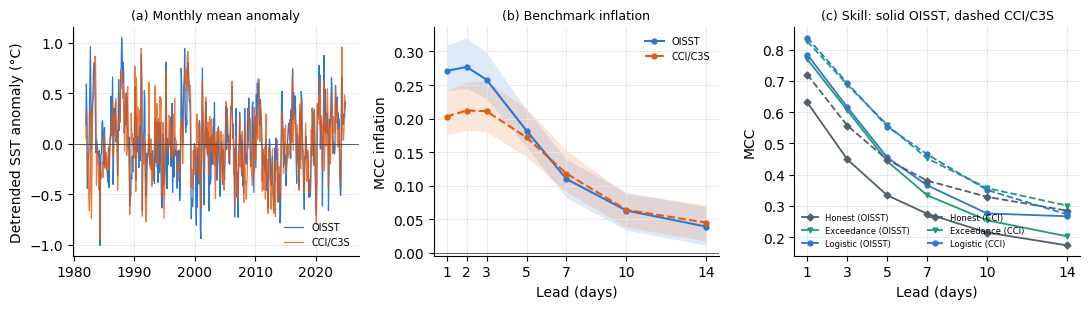

In [ ]:
# ================= V2-4  figure =================
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
mon = pd.DataFrame({'OISST': anomA, 'CCI': anomB}).resample('MS').mean()
axs[0].plot(mon.index, mon.OISST, color='#2a78d6', lw=0.9, label='OISST'); axs[0].plot(mon.index, mon.CCI, color='#e8590c', lw=0.9, alpha=0.8, label='CCI/C3S')
axs[0].axhline(0, color='#444', lw=0.6); axs[0].set_ylabel('Detrended SST anomaly (°C)'); axs[0].set_title('(a) Monthly mean anomaly', fontsize=9)
for name, col, ls in (('OISST', '#2a78d6', '-'), ('CCI', '#e8590c', '--')):
    g = LK[LK.dataset == name]
    axs[1].fill_between(g.lead, g.lo, g.hi, color=col, alpha=0.15, lw=0)
    axs[1].plot(g.lead, g.inflation, ls, marker='o', ms=3.5, color=col, lw=1.5, label='OISST' if name == 'OISST' else 'CCI/C3S')
    g2 = SK[SK.dataset == name]
    for k, (n, mk) in enumerate((('honest', 'D'), ('exceedance', 'v'), ('logistic', 'o'))):
        axs[2].plot(g2.lead, g2[n], ls, marker=mk, ms=3.5, lw=1.3, color=['#52606d', '#1b9e77', '#2a78d6'][k],
                    label=f'{n.capitalize()} ({"OISST" if name == "OISST" else "CCI"})')
axs[1].axhline(0, color='#444', lw=0.6); axs[1].set_xlabel('Lead (days)'); axs[1].set_ylabel('MCC inflation'); axs[1].set_title('(b) Benchmark inflation', fontsize=9)
axs[2].set_xlabel('Lead (days)'); axs[2].set_ylabel('MCC'); axs[2].set_title('(c) Skill: solid OISST, dashed CCI/C3S', fontsize=9)
axs[0].legend(frameon=False, fontsize=7); axs[1].legend(frameon=False, fontsize=7); axs[2].legend(frameon=False, fontsize=6, ncol=2, loc='lower left')
axs[0].xaxis.set_major_locator(mdates.YearLocator(10)); axs[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axs[1].set_xticks(LEADS1); axs[2].set_xticks(LEADS2)
for ax in axs: ax.grid(color='#e6e6e6', lw=0.6); [ax.spines[s].set_visible(False) for s in ('top', 'right')]
fig.tight_layout(); fig.savefig(f'{FIG}/v2_oisst_vs_cci.png', dpi=300); plt.show()


In [ ]:
# ================= V2-5  why do OISST and CCI disagree? (needs only V2-1 in memory, < 1 min) =================
import numpy as np, pandas as pd
A, C = anomA, anomB                                    # detrended daily anomalies from V2-1
# 1. time alignment: the correlation should peak at lag 0
print('anomaly correlation, CCI shifted by k days:', {k: round(float(A.corr(C.shift(k))), 3) for k in range(-3, 4)})
# 2. agreement by time scale
print('correlation of 1-, 7- and 30-day mean anomalies:',
      [round(float(A.rolling(w).mean().corr(C.rolling(w).mean())), 3) for w in (1, 7, 30)])
# 3. persistence and smoothness of each product
for n, x in (('OISST', A), ('CCI', C)):
    print(f'{n:5s} anomaly SD {x.std():.3f} | SD of day-to-day change {x.diff().std():.3f} | '
          f'autocorrelation lag 1/7/14/30: {[round(float(x.autocorr(k)), 3) for k in (1, 7, 14, 30)]}')
# 4. by calendar month
g = pd.DataFrame({'O': A, 'C': C, 'lo': a['label'], 'lc': b['label']}, index=S.index)
mon = g.groupby(g.index.month).apply(lambda d: pd.Series({
    'r': d.O.corr(d.C), 'RMS diff': np.sqrt(((d.C - d.O) ** 2).mean()), 'SD OISST': d.O.std(), 'SD CCI': d.C.std(),
    'MHW days OISST': d.lo.sum(), 'MHW days CCI': d.lc.sum(), 'both': ((d.lo == 1) & (d.lc == 1)).sum()})).round(3)
print('\nby calendar month\n' + mon.to_string())
# 5. by period (raw SST difference shows where the trend difference comes from)
per = pd.cut(S.index.year, [1981, 1991, 2002, 2015, 2024], labels=['1982-1991', '1992-2002', '2003-2015', '2016-2024'])
pp = g.assign(raw_diff=(b['sst'] - a['sst']).values).groupby(per, observed=True).apply(lambda d: pd.Series({
    'mean raw diff CCI-OISST': d.raw_diff.mean(), 'r': d.O.corr(d.C), 'RMS diff': np.sqrt(((d.C - d.O) ** 2).mean()),
    'MHW days OISST': d.lo.sum(), 'MHW days CCI': d.lc.sum(), 'both': ((d.lo == 1) & (d.lc == 1)).sum()})).round(3)
print('\nby period\n' + pp.to_string())
mon.to_csv(f'{PROC}/v2_diag_month.csv'); pp.to_csv(f'{PROC}/v2_diag_period.csv')

anomaly correlation, CCI shifted by k days: {-3: 0.639, -2: 0.686, -1: 0.728, 0: 0.751, 1: 0.743, 2: 0.706, 3: 0.655}
correlation of 1-, 7- and 30-day mean anomalies: [0.751, 0.775, 0.783]
OISST anomaly SD 0.476 | SD of day-to-day change 0.143 | autocorrelation lag 1/7/14/30: [0.955, 0.575, 0.395, 0.297]
CCI   anomaly SD 0.447 | SD of day-to-day change 0.109 | autocorrelation lag 1/7/14/30: [0.97, 0.608, 0.381, 0.292]

by calendar month
        r  RMS diff  SD OISST  SD CCI  MHW days OISST  MHW days CCI  both
1   0.798     0.242     0.392   0.366            54.0          75.0  48.0
2   0.879     0.226     0.473   0.410            59.0          71.0  43.0
3   0.839     0.266     0.490   0.416            77.0          78.0  49.0
4   0.814     0.309     0.531   0.454           113.0         107.0  67.0
5   0.815     0.385     0.644   0.619           150.0         158.0  97.0
6   0.626     0.406     0.446   0.488           102.0         116.0  17.0
7   0.608     0.368     0.414   0.418    